# TA-06: Eksplorasi Mendalam Algoritma Random Forest
**Studi kasus:** Prediksi Customer Churn (Telco Customer Churn, dataset populer di Kaggle: *blastchar/telco-customer-churn*)

**Peran:** Data Scientist yang membangun model prediksi stabil dan *explainable* untuk mengidentifikasi pelanggan yang berisiko berhenti berlangganan.

## 1. Persiapan Data & Preprocessing

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, json
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('telco.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
print('\nMissing value per kolom (setelah konversi TotalCharges):')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isna().sum()[df.isna().sum() > 0])
print(df[df['TotalCharges'].isna()][['tenure','MonthlyCharges','TotalCharges']].head())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` kosong hanya pada pelanggan baru (`tenure = 0`), artinya belum pernah ditagih, sehingga diisi **0**.

In [3]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df = df.drop(columns=['customerID'])          # ID tidak informatif
df['Churn'] = df['Churn'].map({'No':0, 'Yes':1})

# Encoding: One-Hot untuk semua kolom kategori
cat_cols = df.select_dtypes(include='object').columns.tolist()
print('Kolom kategori:', cat_cols)
X = pd.get_dummies(df.drop(columns='Churn'), columns=cat_cols, drop_first=True).astype(float)
y = df['Churn']
print('Shape fitur setelah encoding:', X.shape)

Kolom kategori: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Shape fitur setelah encoding: (7043, 30)


### Analisis awal: ketidakseimbangan kelas

Churn
0    5174
1    1869
Name: count, dtype: int64 
 Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


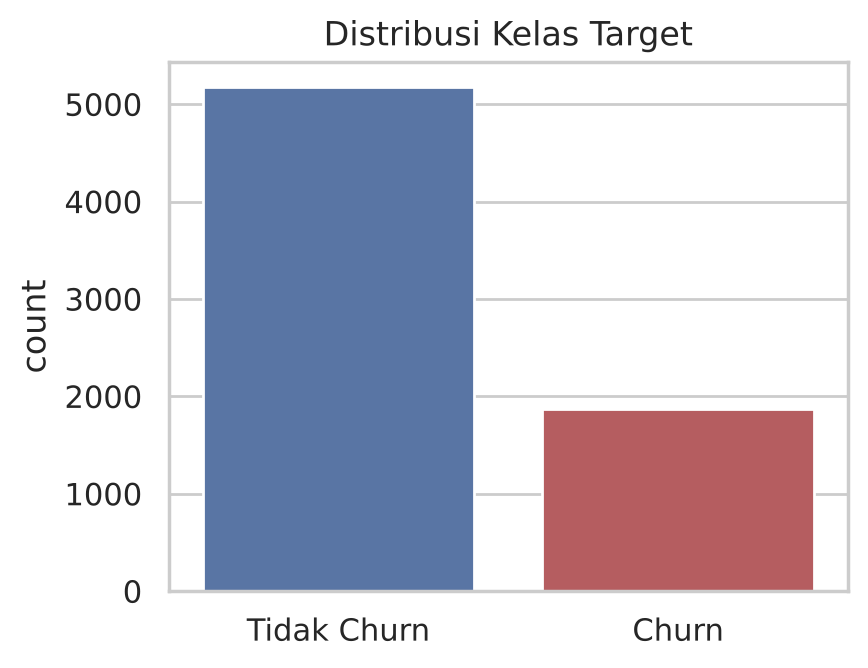

In [4]:
counts = y.value_counts()
print(counts, '\n', (y.value_counts(normalize=True)*100).round(2))
fig, ax = plt.subplots(figsize=(4.5,3.5))
sns.countplot(x=y.map({0:'Tidak Churn',1:'Churn'}), ax=ax, palette=['#4C72B0','#C44E52'])
ax.set_title('Distribusi Kelas Target'); ax.set_xlabel(''); plt.tight_layout()
plt.savefig('fig_class_dist.png', dpi=150); plt.show()

Data **tidak seimbang** (~73% tidak churn vs ~27% churn). Karena itu, selain akurasi, kita juga memperhatikan *recall* dan F1-score kelas churn. Pembagian data memakai `stratify=y` agar proporsi kelas terjaga.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi churn train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

Train: (5634, 30) | Test: (1409, 30)
Proporsi churn train: 0.265 | test: 0.265


## 2. Modeling & Eksperimen Hyperparameter
### Skenario A: Pengaruh Jumlah Pohon (`n_estimators`)

In [6]:
n_list = [10, 50, 100, 200, 500]
resA = []
for n in n_list:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    cv = cross_val_score(RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1), X_train, y_train, cv=5).mean()
    resA.append({'n_estimators': n,
                 'Akurasi Train': accuracy_score(y_train, rf.predict(X_train)),
                 'Akurasi Test': accuracy_score(y_test, rf.predict(X_test)),
                 'CV 5-fold (train)': cv})
resA = pd.DataFrame(resA); resA.round(4)

,n_estimators,Akurasi Train,Akurasi Test,CV 5-fold (train)
0,10,0.9799,0.7814,0.7744
1,50,0.9973,0.7871,0.7813
2,100,0.9980,0.7850,0.7884
3,200,0.9980,0.7928,0.7861
4,500,0.9980,0.7963,0.7893


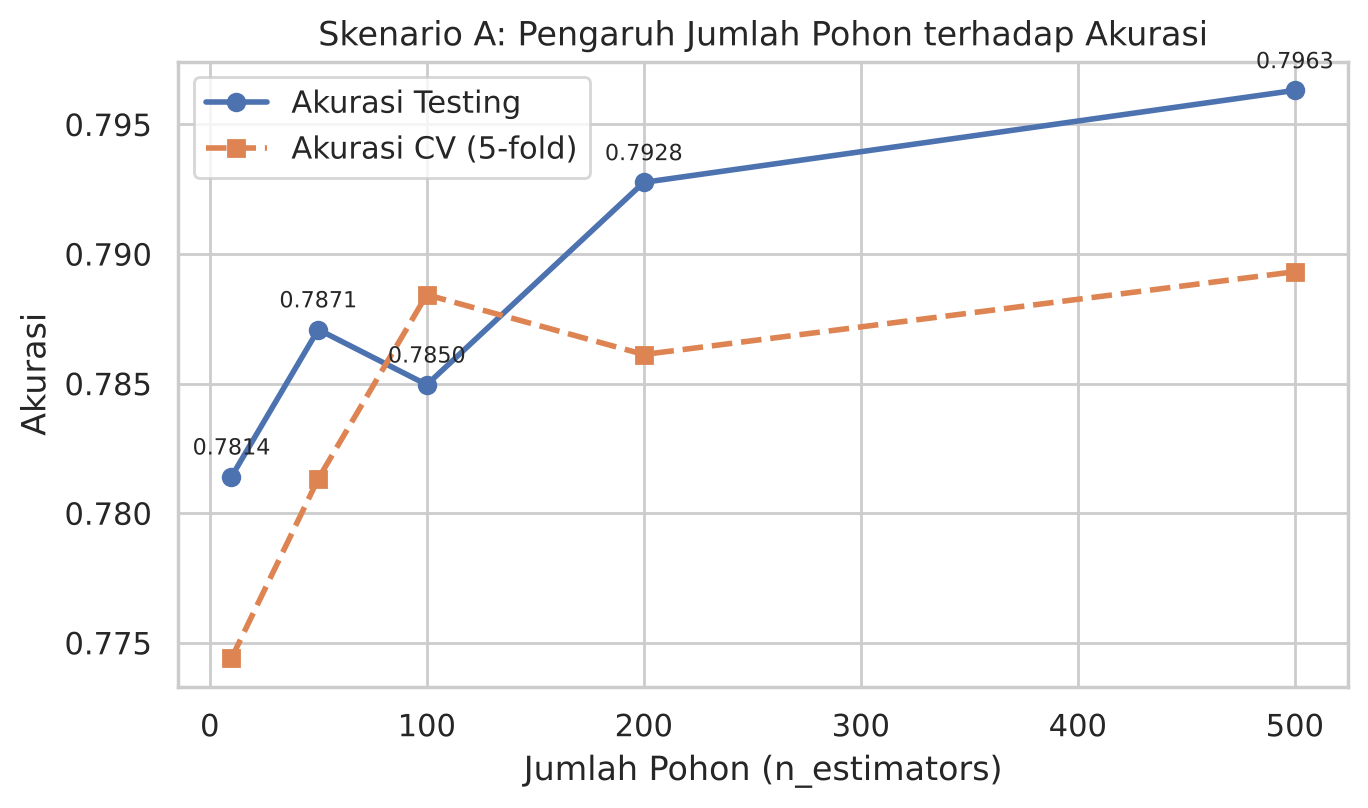

n_estimators terbaik (akurasi testing tertinggi): 500


In [7]:
fig, ax = plt.subplots(figsize=(7,4.2))
ax.plot(resA['n_estimators'], resA['Akurasi Test'], 'o-', lw=2, label='Akurasi Testing')
ax.plot(resA['n_estimators'], resA['CV 5-fold (train)'], 's--', lw=2, label='Akurasi CV (5-fold)')
for x_, y_ in zip(resA['n_estimators'], resA['Akurasi Test']): ax.annotate(f'{y_:.4f}', (x_, y_), textcoords='offset points', xytext=(0,8), ha='center', fontsize=8)
ax.set_xlabel('Jumlah Pohon (n_estimators)'); ax.set_ylabel('Akurasi'); ax.set_title('Skenario A: Pengaruh Jumlah Pohon terhadap Akurasi')
ax.legend(); plt.tight_layout(); plt.savefig('fig_skenarioA.png', dpi=150); plt.show()

best_n = int(resA.loc[resA['Akurasi Test'].idxmax(), 'n_estimators'])
print('n_estimators terbaik (akurasi testing tertinggi):', best_n)

**Analisis Skenario A.** Akurasi testing naik dari 78,1% (10 pohon) menjadi 79,6% (500 pohon), tetapi sekitar separuh kenaikan terjadi di awal (10 ke 50 pohon). Dari 50 sampai 500 pohon, akurasi hanya berfluktuasi kecil (sekitar 78,5% sampai 79,6%), dan akurasi CV 5-fold nyaris datar (78,1% sampai 78,9%). Jadi menambah pohon terus-menerus **tidak** meningkatkan akurasi secara signifikan, sementara biaya training, prediksi, dan memori terus naik. Ini sesuai teori: Random Forest tidak overfit karena menambah pohon, hanya mengalami *diminishing returns*. Nilai terbaik menurut akurasi testing adalah 500 pohon, dan itu yang dipakai di Skenario B (100 pohon sebenarnya sudah hampir setara).

### Skenario B: Pengaruh Kedalaman Pohon (`max_depth`)

In [8]:
depth_list = [None, 3, 5, 10, 20]
resB = []
for d in depth_list:
    rf = RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=42, n_jobs=-1).fit(X_train, y_train)
    tr, te = accuracy_score(y_train, rf.predict(X_train)), accuracy_score(y_test, rf.predict(X_test))
    cv = cross_val_score(RandomForestClassifier(n_estimators=best_n, max_depth=d, random_state=42, n_jobs=-1), X_train, y_train, cv=5).mean()
    resB.append({'max_depth': 'None' if d is None else d, 'Akurasi Train': tr, 'Akurasi Test': te, 'Gap (Train-Test)': tr-te, 'CV 5-fold (train)': cv})
resB = pd.DataFrame(resB); resB.round(4)

,max_depth,Akurasi Train,Akurasi Test,Gap (Train-Test),CV 5-fold (train)
0,None,0.9980,0.7963,0.2017,0.7893
1,3,0.7856,0.7800,0.0056,0.7838
2,5,0.8016,0.7899,0.0116,0.7950
3,10,0.8665,0.8034,0.0631,0.7968
4,20,0.9980,0.7921,0.2060,0.7881


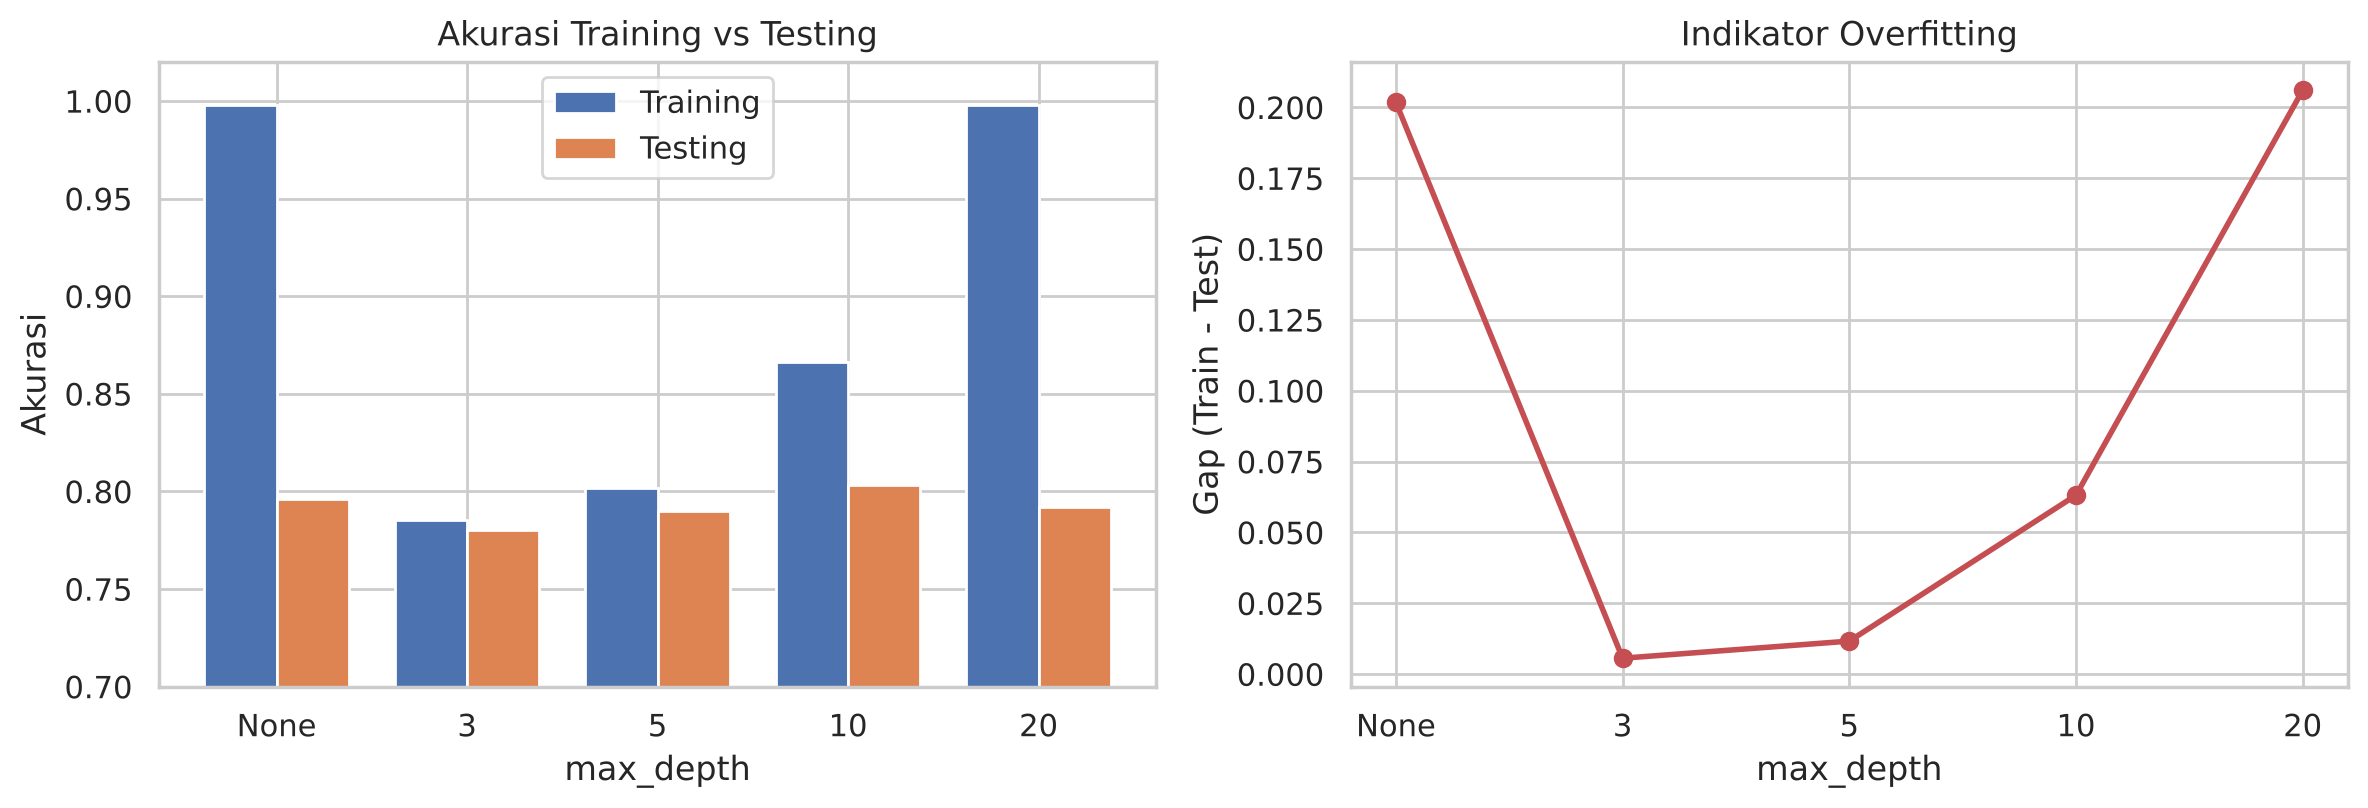

max_depth terbaik (CV tertinggi, gap kecil): 10


In [9]:
labels = resB['max_depth'].astype(str).tolist()
fig, axes = plt.subplots(1, 2, figsize=(12,4.2))
w, xs = 0.38, np.arange(len(labels))
axes[0].bar(xs-w/2, resB['Akurasi Train'], w, label='Training', color='#4C72B0')
axes[0].bar(xs+w/2, resB['Akurasi Test'], w, label='Testing', color='#DD8452')
axes[0].set_xticks(xs); axes[0].set_xticklabels(labels); axes[0].set_ylim(0.7,1.02)
axes[0].set_xlabel('max_depth'); axes[0].set_ylabel('Akurasi'); axes[0].set_title('Akurasi Training vs Testing'); axes[0].legend()
axes[1].plot(labels, resB['Gap (Train-Test)'], 'o-', color='#C44E52', lw=2)
axes[1].set_xlabel('max_depth'); axes[1].set_ylabel('Gap (Train - Test)'); axes[1].set_title('Indikator Overfitting')
plt.tight_layout(); plt.savefig('fig_skenarioB.png', dpi=150); plt.show()

best_row = resB.loc[resB['CV 5-fold (train)'].idxmax()]
best_depth = None if best_row['max_depth']=='None' else int(best_row['max_depth'])
print('max_depth terbaik (CV tertinggi, gap kecil):', best_depth)

**Analisis Skenario B.** Pada `max_depth=None` dan `20`, akurasi training 99,8% sementara akurasi testing hanya sekitar 79%, gap sekitar 20 poin: ini tanda jelas **overfitting**. Pada kedalaman 3 dan 5 gap kecil (0,6 sampai 1,2 poin) tetapi akurasi masih rendah karena model terlalu sederhana (*underfit*). Titik terbaik ada pada `max_depth=10`: akurasi testing tertinggi (80,3%) dan CV tertinggi (79,7%) dengan gap yang moderat (6,3 poin). Overfitting mulai terlihat jelas di kedalaman antara 10 dan 20. Pemilihan `max_depth` memakai **CV 5-fold pada data training** agar tidak memilih berdasarkan data uji.

## 3. Analisis Feature Importance

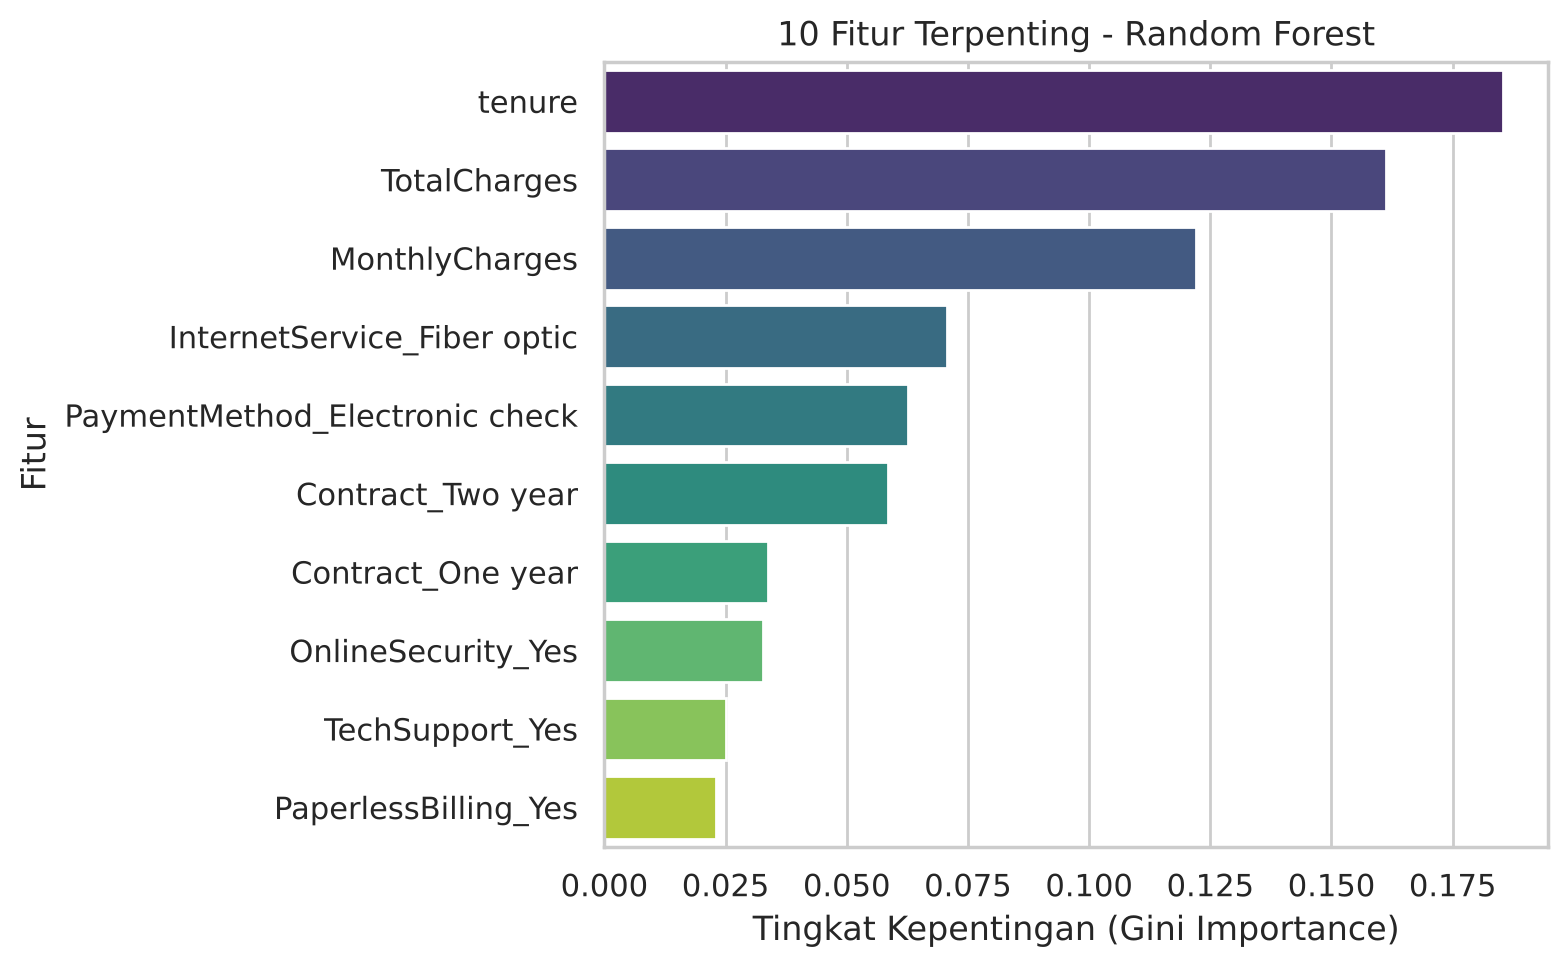

tenure                            0.1854
TotalCharges                      0.1613
MonthlyCharges                    0.1221
InternetService_Fiber optic       0.0707
PaymentMethod_Electronic check    0.0626
Contract_Two year                 0.0584
Contract_One year                 0.0338
OnlineSecurity_Yes                0.0328
TechSupport_Yes                   0.0252
PaperlessBilling_Yes              0.0230
dtype: float64

In [10]:
best_model = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=42, n_jobs=-1).fit(X_train, y_train)
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
top10 = imp.head(10)
fig, ax = plt.subplots(figsize=(8,5))
sns.barplot(x=top10.values, y=top10.index, ax=ax, palette='viridis')
ax.set_xlabel('Tingkat Kepentingan (Gini Importance)'); ax.set_ylabel('Fitur'); ax.set_title('10 Fitur Terpenting - Random Forest')
plt.tight_layout(); plt.savefig('fig_importance.png', dpi=150); plt.show()
top10.round(4)

**Interpretasi.** Fitur dominan hasil model: `tenure` (lama berlangganan, 0,185), `TotalCharges` (0,161), `MonthlyCharges` (0,122), `InternetService_Fiber optic`, `PaymentMethod_Electronic check`, dan `Contract_Two year`. (Kategori `Month-to-month` tidak muncul karena menjadi kategori acuan pada `drop_first=True`.)
- **tenure / TotalCharges:** pelanggan baru paling rawan churn, sedangkan pelanggan lama sudah loyal. Sesuai teori *customer lifecycle*.
- **Contract:** kontrak bulanan tidak punya *switching cost*, sedangkan kontrak 1-2 tahun mengikat pelanggan.
- **MonthlyCharges & Fiber optic:** tagihan tinggi dan layanan fiber berkorelasi dengan churn, kemungkinan karena sensitivitas harga.
- **Electronic check:** sering menjadi proksi pelanggan yang kurang terikat (tanpa autopay).

Semua selaras dengan intuisi domain telekomunikasi. *Catatan:* importance menunjukkan **kontribusi prediktif**, bukan hubungan sebab-akibat.

## 4. Evaluasi Akhir & Kesimpulan

Konfigurasi terbaik: n_estimators=500, max_depth=10
Akurasi Train: 0.8665 | Akurasi Test: 0.8034

              precision    recall  f1-score   support

 Tidak Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



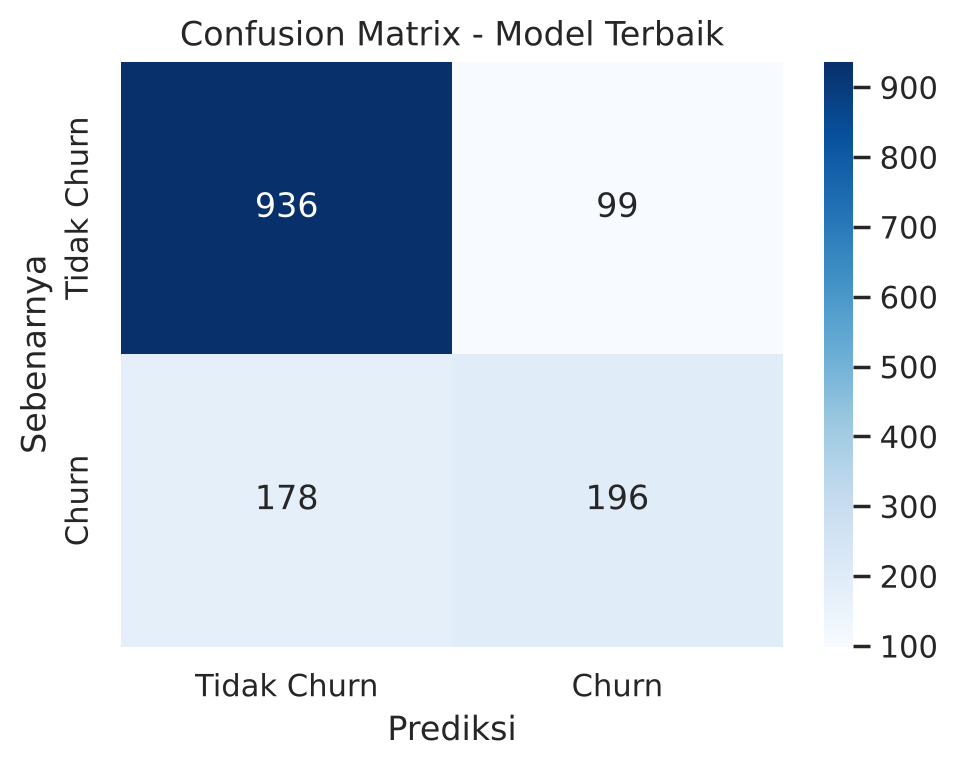

In [11]:
y_pred = best_model.predict(X_test)
print(f'Konfigurasi terbaik: n_estimators={best_n}, max_depth={best_depth}')
print('Akurasi Train: %.4f | Akurasi Test: %.4f\n' % (accuracy_score(y_train, best_model.predict(X_train)), accuracy_score(y_test, y_pred)))
print(classification_report(y_test, y_pred, target_names=['Tidak Churn','Churn']))
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Tidak Churn','Churn'], yticklabels=['Tidak Churn','Churn'], ax=ax)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title('Confusion Matrix - Model Terbaik')
plt.tight_layout(); plt.savefig('fig_cm.png', dpi=150); plt.show()

### Bonus: Threshold Tuning untuk Meningkatkan Recall Churn

In [12]:
proba = best_model.predict_proba(X_test)[:,1]
from sklearn.metrics import precision_score, recall_score, f1_score
rows=[]
for t in [0.5,0.4,0.35,0.3]:
    p=(proba>=t).astype(int)
    rows.append({'threshold':t,'Precision (Churn)':precision_score(y_test,p),'Recall (Churn)':recall_score(y_test,p),'F1 (Churn)':f1_score(y_test,p),'Akurasi':accuracy_score(y_test,p)})
pd.DataFrame(rows).round(3)

,threshold,Precision (Churn),Recall (Churn),F1 (Churn),Akurasi
0,0.50,0.664,0.524,0.586,0.803
1,0.40,0.597,0.652,0.623,0.791
2,0.35,0.551,0.717,0.623,0.770
3,0.30,0.526,0.783,0.629,0.755


### Kesimpulan
- **Konfigurasi terbaik:** `n_estimators=500`, `max_depth=10` dengan akurasi testing 80,3% (akurasi training 86,7%). Untuk efisiensi, `n_estimators=100` memberi hasil hampir setara.
- **n_estimators:** peningkatan akurasi kecil dan cepat jenuh setelah puluhan pohon; menambah hingga 500 terutama menambah biaya komputasi.
- **max_depth:** tanpa pembatasan (`None`/20) menyebabkan overfitting (gap sekitar 20 poin); kedalaman 3 sampai 5 underfit; kedalaman 10 paling seimbang.
- **Class imbalance:** recall kelas churn hanya 0,52 pada threshold 0,5. Menurunkan threshold menjadi 0,30 menaikkan recall churn menjadi 0,78 (F1 churn naik dari 0,59 ke 0,63) dengan akurasi turun ke 75,5%, trade-off yang wajar untuk kampanye retensi.
- **Business insight:** fokuskan program retensi pada pelanggan **kontrak bulanan, tenure rendah, tagihan bulanan tinggi (fiber optic), dan pembayaran electronic check**. Tawarkan insentif migrasi ke kontrak 1-2 tahun dan autopay.

## 5. Simpan Model untuk Deployment Web

In [13]:
joblib.dump({'model': best_model, 'columns': X.columns.tolist()}, 'rf_churn_model.joblib')
res = {'best_n': best_n, 'best_depth': best_depth, 'test_acc': float(accuracy_score(y_test, y_pred))}
json.dump(res, open('best_config.json','w')); print(res)

{'best_n': 500, 'best_depth': 10, 'test_acc': 0.8034066713981547}
